# Waste Classifier — Training & Evaluation

Klasifikasi gambar sampah ke **3 kelas**: `organic`, `paper`, `plastic`.

- Dataset: Kaggle *Garbage Classification (12 classes)* (`mostafaabla/garbage-classification`), diproses oleh `scripts/prepare_dataset.py` (mapping kelas, hapus duplikat, 600 gambar/kelas, split 70/15/15).
- Model: **MobileNetV2** (ImageNet) + transfer learning, input 224×224.
- Tahap 1: base dibekukan, hanya head yang dilatih. Tahap 2: fine-tune 30 layer terakhir dengan learning rate kecil.
- Output: `models/waste_classifier.keras`, `models/waste_classifier.tflite`, dan `reports/*`.

In [1]:
import json, os, random
from pathlib import Path

import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
REPORTS = ROOT / "reports"; REPORTS.mkdir(exist_ok=True)

IMG_SIZE = (224, 224)
BATCH = 32
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793844670.526709   24661 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793844672.081598   24661 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load dataset

In [2]:
def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        DATA / split, image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED,
    )

train_ds = load("train", True)
val_ds = load("val", False)
test_ds = load("test", False)
CLASS_NAMES = train_ds.class_names
print("Classes:", CLASS_NAMES)
print(json.dumps(json.loads((DATA / "summary.json").read_text())["classes"], indent=1))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 1260 files belonging to 3 classes.


Found 270 files belonging to 3 classes.


Found 270 files belonging to 3 classes.


Classes: ['organic', 'paper', 'plastic']
{
 "organic": {
  "sources": [
   "biological"
  ],
  "available_unique": {
   "biological": 985
  },
  "duplicates_removed": 0,
  "total": 600,
  "train": 420,
  "val": 90,
  "test": 90
 },
 "plastic": {
  "sources": [
   "plastic"
  ],
  "available_unique": {
   "plastic": 865
  },
  "duplicates_removed": 0,
  "total": 600,
  "train": 420,
  "val": 90,
  "test": 90
 },
 "paper": {
  "sources": [
   "paper",
   "cardboard"
  ],
  "available_unique": {
   "paper": 1050,
   "cardboard": 891
  },
  "duplicates_removed": 0,
  "total": 600,
  "train": 420,
  "val": 90,
  "test": 90
 }
}


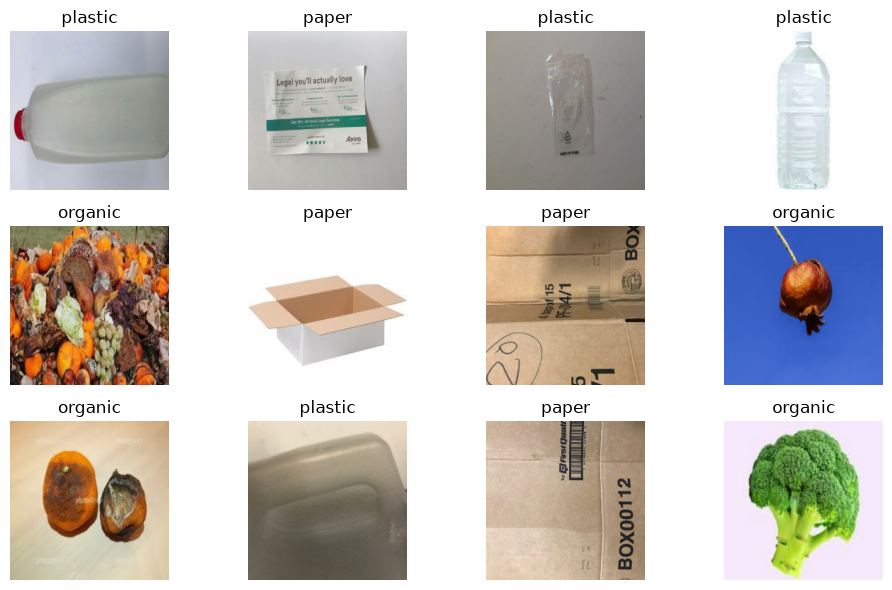

In [3]:
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]])
        plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Model

Preprocessing (scaling ke [-1, 1] sesuai MobileNetV2) dan augmentasi dimasukkan ke dalam model.
Jadi API cukup mengirim gambar RGB 224×224 dengan nilai 0–255. Layer augmentasi otomatis nonaktif saat inference.

In [4]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.15),
], name="augmentation")

base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
x = augment(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenet_preprocess")(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax", name="probabilities")(x)
model = keras.Model(inputs, outputs, name="waste_classifier")
model.summary(show_trainable=True)

Model: "waste_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenet_preprocess        │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ probabilities (Dense)       │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Tahap 1: latih head (base dibekukan)

In [5]:
def callbacks(tag):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(str(MODELS / f"checkpoint_{tag}.keras"), monitor="val_accuracy", save_best_only=True),
    ]

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks("stage1"))

Epoch 1/12


/home/asadel/kuliah/lomba/smstr6/guido/dataset_rup/vinara-money-classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/40 ━━━━━━━━━━━━━━━━━━━━ 5:51 9s/step - accuracy: 0.4062 - loss: 1.4400

 2/40 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.3906 - loss: 1.4948

 3/40 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.3750 - loss: 1.4982

 4/40 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.3984 - loss: 1.3564

... (484 outputs left out)

37/40 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9738 - loss: 0.0733

38/40 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9737 - loss: 0.0733

39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9744 - loss: 0.0726

40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.9746 - loss: 0.0723 - val_accuracy: 0.9593 - val_loss: 0.1088 - learning_rate: 0.0010


## 4. Tahap 2: fine-tune 30 layer terakhir

In [6]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
# BatchNorm tetap dibekukan agar statistik ImageNet tidak rusak oleh batch kecil.
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
start = len(hist1.history["loss"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=start + 10, initial_epoch=start, callbacks=callbacks("stage2"))

Epoch 13/22


 1/40 ━━━━━━━━━━━━━━━━━━━━ 4:35 7s/step - accuracy: 1.0000 - loss: 0.0542

 2/40 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - accuracy: 0.9844 - loss: 0.0521

 3/40 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.9688 - loss: 0.0639

 4/40 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.9609 - loss: 0.1054

 5/40 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.9688 - loss: 0.0911

... (278 outputs left out)

37/40 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9856 - loss: 0.0356

38/40 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9852 - loss: 0.0377

39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9856 - loss: 0.0369

40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.9857 - loss: 0.0369 - val_accuracy: 0.9593 - val_loss: 0.1024 - learning_rate: 3.0000e-06


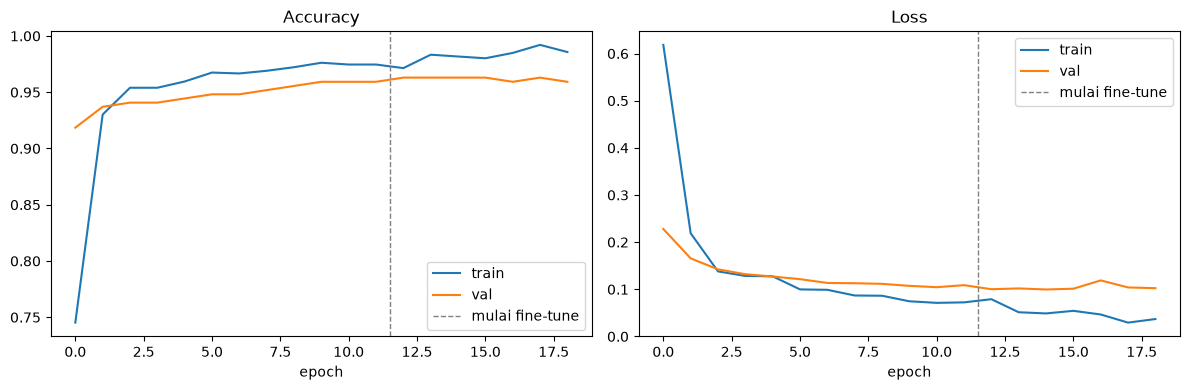

In [7]:
history = {k: hist1.history[k] + hist2.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(history[metric], label="train")
    ax.plot(history["val_" + metric], label="val")
    ax.axvline(start - 0.5, color="gray", ls="--", lw=1, label="mulai fine-tune")
    ax.set_title(metric.capitalize()); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "training_curves.png", dpi=120); plt.show()

## 5. Evaluasi pada test set (data yang tidak pernah dilihat saat training)

In [8]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.4f}  ({(y_true == y_pred).sum()}/{len(y_true)})")

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)
(REPORTS / "classification_report.txt").write_text(f"Test accuracy: {test_acc:.4f}\n\n{report}")

Test accuracy: 0.9704  (262/270)
              precision    recall  f1-score   support

     organic     1.0000    1.0000    1.0000        90
       paper     0.9659    0.9444    0.9551        90
     plastic     0.9457    0.9667    0.9560        90

    accuracy                         0.9704       270
   macro avg     0.9705    0.9704    0.9704       270
weighted avg     0.9705    0.9704    0.9704       270



403

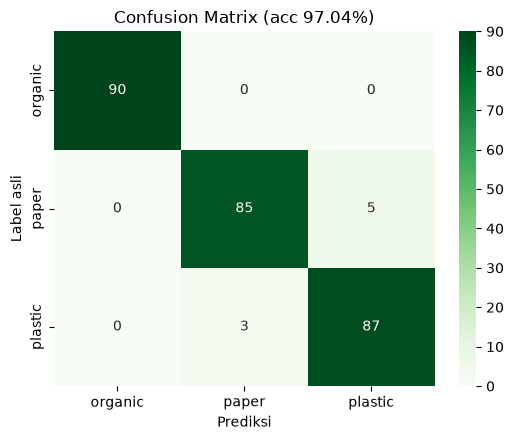

In [9]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi"); plt.ylabel("Label asli"); plt.title(f"Confusion Matrix (acc {test_acc:.2%})")
plt.tight_layout(); plt.savefig(REPORTS / "confusion_matrix.png", dpi=120); plt.show()

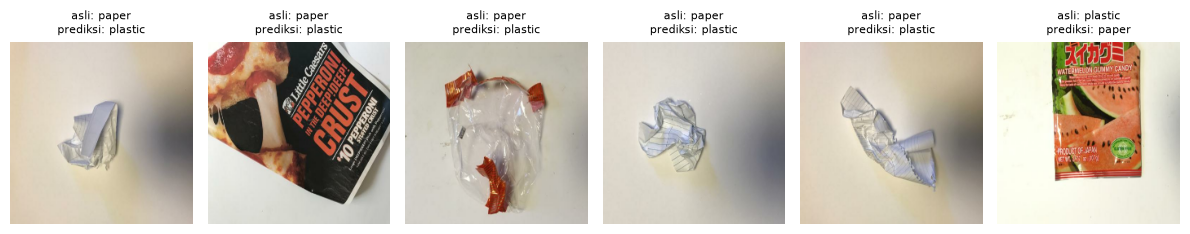

8 prediksi salah dari 270


In [10]:
# Contoh prediksi yang salah, untuk analisis kelas yang sering tertukar.
wrong = np.where(y_true != y_pred)[0]
images = np.concatenate([x.numpy() for x, _ in test_ds])
plt.figure(figsize=(12, 3))
for i, idx in enumerate(wrong[:6]):
    plt.subplot(1, 6, i + 1)
    plt.imshow(images[idx].astype("uint8"))
    plt.title(f"asli: {CLASS_NAMES[y_true[idx]]}\nprediksi: {CLASS_NAMES[y_pred[idx]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()
print(f"{len(wrong)} prediksi salah dari {len(y_true)}")

## 6. Simpan model + metrik

In [11]:
keras_path = MODELS / "waste_classifier.keras"
model.save(keras_path)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_path = MODELS / "waste_classifier.tflite"
tflite_path.write_bytes(converter.convert())

(MODELS / "labels.json").write_text(json.dumps(CLASS_NAMES))

per_class = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
metrics = {
    "model": "MobileNetV2 transfer learning",
    "input_size": list(IMG_SIZE),
    "classes": CLASS_NAMES,
    "test_accuracy": round(float(test_acc), 4),
    "test_samples": int(len(y_true)),
    "per_class": {c: {k: round(v, 4) for k, v in per_class[c].items()} for c in CLASS_NAMES},
    "macro_f1": round(per_class["macro avg"]["f1-score"], 4),
    "confusion_matrix": cm.tolist(),
    "epochs_trained": len(history["loss"]),
}
(REPORTS / "metrics.json").write_text(json.dumps(metrics, indent=2))

for f in MODELS.glob("checkpoint_*.keras"):
    f.unlink()
print(json.dumps({k: metrics[k] for k in ["test_accuracy", "macro_f1", "epochs_trained"]}))
print(f"keras: {keras_path.stat().st_size/1e6:.1f} MB | tflite: {tflite_path.stat().st_size/1e6:.1f} MB")

INFO:tensorflow:Assets written to: /tmp/tmprjcn91y9/assets


INFO:tensorflow:Assets written to: /tmp/tmprjcn91y9/assets


Saved artifact at '/tmp/tmprjcn91y9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  140273834549968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834552848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834553040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834552272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834547280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834550352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834553616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834554576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834554192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834551888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140273834552464: Tens

{"test_accuracy": 0.9704, "macro_f1": 0.9704, "epochs_trained": 19}
keras: 21.8 MB | tflite: 2.5 MB


In [12]:
# Cek: TFLite memberi hasil yang sama dengan model Keras.
interp = tf.lite.Interpreter(model_path=str(tflite_path))
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
agree = 0
for i in range(len(images)):
    interp.set_tensor(inp["index"], images[i : i + 1].astype(np.float32))
    interp.invoke()
    agree += int(interp.get_tensor(out["index"]).argmax() == y_pred[i])
print(f"TFLite vs Keras agreement: {agree}/{len(images)}")

/home/asadel/kuliah/lomba/smstr6/guido/dataset_rup/vinara-money-classifier/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


TFLite vs Keras agreement: 266/270
